# Robustness Analysis

This notebook evaluates the robustness of three binary classification models for heart disease prediction: Logistic Regression, Random Forest, and a Multi-Layer Perceptron (MLP).

Each model is evaluated across five experiments with different random seeds to assess the variability of its performance.

The main objective is to maximize recall while maintaining a minimum precision of 0.5.

In [18]:
# Standard library
import sys

sys.path.append("..")

# Third-party libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import precision_recall_curve

# Project modules
from src.experiment import run_experiment

## Experimental Setup

Run the same training, threshold selection, and evaluation procedure across five experiments using different random seeds.

For each experiment, the dataset is split into training (70%), validation (15%), and test (15%) sets using stratified sampling.

The decision threshold is selected on the validation set to maximize recall while maintaining a minimum precision of 0.5. The selected threshold is then applied to the test set.

In [19]:
random_states = [40, 41, 42, 43, 44]

all_results = []

for seed in random_states:
    results = run_experiment(seed)
    all_results.append(results)

KeyboardInterrupt: 

## Results Summary

Compute the mean and standard deviation of each evaluation metric across the five experiments for each model.

This provides an overview of the average performance and variability of the models across different data splits.

In [ ]:
models = [
    "Logistic Regression",
    "Random Forest",
    "MLP"
]

metrics_summary = {}

for model in models:
    metrics = pd.DataFrame([
        result[model]["metrics"] for result in all_results
    ])

    metrics_summary[model] = {
        metric: (
            f"{metrics[metric].mean():.4f} "
            f"± {metrics[metric].std(ddof=1):.4f}"
        )
        for metric in metrics.columns
    }

summary_table = pd.DataFrame.from_dict(
    metrics_summary,
    orient="index"
)

summary_table.index.name = "Model"

display(summary_table)

,Threshold,Loss,Accuracy,Precision,Recall,F1-score,Average Precision
Model,,,,,,,
Logistic Regression,0.1470 ± 0.0410,0.3376 ± 0.0972,0.7644 ± 0.0696,0.6846 ± 0.0706,0.9524 ± 0.0673,0.7927 ± 0.0425,0.9351 ± 0.0352
Random Forest,0.2306 ± 0.1050,0.3594 ± 0.0409,0.7511 ± 0.0596,0.6926 ± 0.0914,0.9048 ± 0.1347,0.7729 ± 0.0346,0.9344 ± 0.0252
MLP,0.1488 ± 0.0380,0.3420 ± 0.0880,0.7244 ± 0.1243,0.6537 ± 0.1019,0.9429 ± 0.0621,0.7675 ± 0.0777,0.9306 ± 0.0383


## Precision-Recall Curve Comparison

Compare the mean precision-recall curves across the five experiments for each model.

The curves are interpolated onto a common recall grid before averaging, allowing the models' precision-recall trade-offs to be compared across different experiments and decision thresholds.

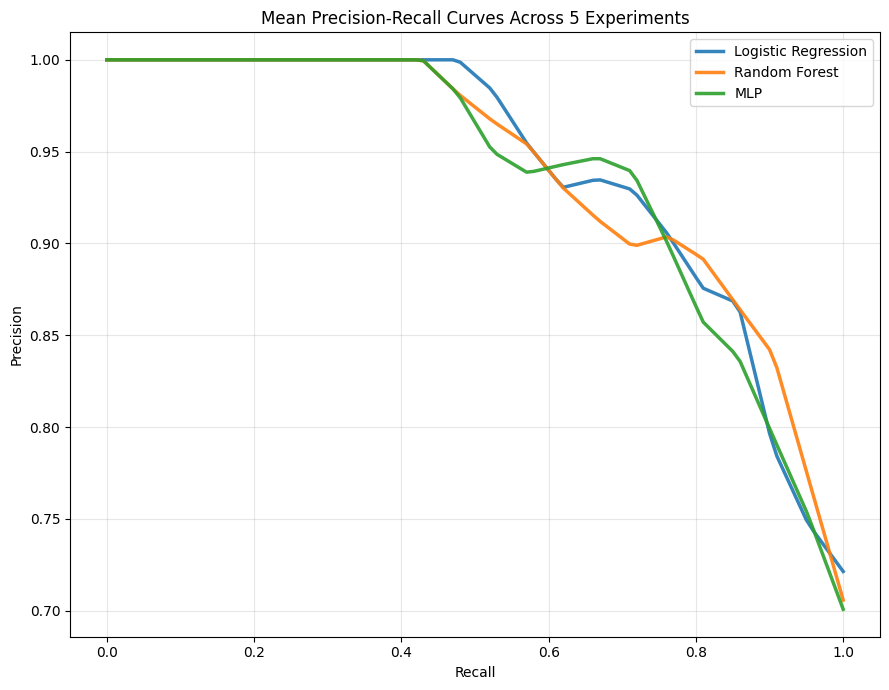

In [ ]:
recall_grid = np.linspace(0, 1, 101)

plt.figure(figsize=(9, 7))

for model in models:
    interpolated_precisions = []

    for result in all_results:
        y_true = result[model]["y_true"]
        y_proba = result[model]["y_proba"]

        precision, recall, _ = precision_recall_curve(
            y_true, y_proba
        )

        recall_ascending = recall[::-1]
        precision_ascending = precision[::-1]

        recall_unique, indices = np.unique(
            recall_ascending, return_index=True
        )
        precision_unique = precision_ascending[indices]

        interpolated_precision = np.interp(
            recall_grid,
            recall_unique,
            precision_unique
        )

        interpolated_precisions.append(interpolated_precision)

    interpolated_precisions = np.array(interpolated_precisions)
    mean_precision = interpolated_precisions.mean(axis=0)

    plt.plot(
        recall_grid,
        mean_precision,
        label=model,
        linewidth=2.5,
        alpha=0.9
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Mean Precision-Recall Curves Across 5 Experiments")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Results Analysis